[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aranaur/aranaur.rbind.io/blob/main/lectures/kse/MATH840/26autumn/labs/_demo09_uk.ipynb)

# MATH840 — Практика тижня 9: коли однієї моделі замало

**Заняття не оцінюється.** Чотири кейси з інструментами лекції *Advanced Forecasting Methods* — кілька
сезонів, Prophet, тижневі дані, комбінації та їхні інтервали, — і кожну нову модель ставимо поруч зі
знайомими: сезонний наївний, ETS, ARIMA, Theta. Сьогоднішня **Lab 8** — це кейс 4 на вашому власному ряді.

| Кейс | Історія | Чого вчить | Хв |
|---|---|---|---|
| 0 | — | інструменти: один бектест для будь-якого прогнозиста | 5 |
| 1 | ⚡ Рік добового попиту на електрику у Вікторії | два сезони й погода: кому що потрібно | 25 |
| 2 | 🛒 Walmart, 45 магазинів, тиждень за тижнем | $m = 52{,}18$: MSTL, гармоніки й Prophet проти минулорічного тижня | 20 |
| 3 | 🏨 Поїздки до 76 регіонів Австралії | обрати одну модель чи усереднити? | 15 |
| 4 | 🍽️ Австралійці їдять поза домом | рецепт Lab 8 від початку до кінця: комбінація, потім чесний інтервал | 20 |

Перед кожним результатом стоїть 🔮 — спершу вгадайте, потім запускайте клітинку. Кожен кейс закінчується
питанням; відповіді — одразу під ним.

## 0. Налаштування та інструменти

In [1]:
!pip install -q statsforecast==2.1.1 great_tables prophet

import os
os.environ["NIXTLA_ID_AS_COL"] = "true"
import logging
import warnings
warnings.filterwarnings("ignore")
for name in ("cmdstanpy", "prophet"):
    logging.getLogger(name).setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from great_tables import GT, loc, style
from matplotlib.colors import LinearSegmentedColormap, to_hex
from prophet import Prophet
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, AutoETS, AutoTheta, MSTL, SeasonalNaive

plt.rcParams.update({"figure.figsize": (11, 3.6), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

BASE = ("https://raw.githubusercontent.com/Aranaur/aranaur.rbind.io/"
        "main/lectures/kse/MATH840/26autumn/data")
COLOURS = {"actual": "#314f4f", "a": "#e64173", "b": "#20B2AA", "c": "#FFA500", "d": "#6A5ACD"}

Чотири інструменти на все заняття. Головний — `backtest`: він приймає **будь-який** прогнозист — функцію,
яка за точкою початку повертає наступні `h` значень, — тож ETS, гармонічну регресію і Prophet оцінюємо
за одним і тим самим правилом.

In [2]:
def fourier(t, period, K):
    # Week 5's Fourier terms; the period may be any number, 7, 365.25 or 52.18.
    return np.column_stack([f(2 * np.pi * k * t / period) for k in range(1, K + 1) for f in (np.sin, np.cos)])


def backtest(y, forecasters, origins, h, scale, labels=None):
    # MASE of every forecaster from every origin; also returns the forecasts, for the plots.
    forecasts = {name: [np.asarray(f(e)) for e in origins] for name, f in forecasters.items()}
    table = pd.DataFrame({name: [np.mean(np.abs(y[e:e + h] - fc)) / scale for e, fc in zip(origins, fcs)]
                          for name, fcs in forecasts.items()}, index=labels or origins).T
    table["mean"] = table.mean(axis=1)
    return table, forecasts


def winkler(y, lo, hi, alpha=0.2):
    # Width of the interval, plus 2/alpha times every miss (lecture, Week 8).
    return float(np.mean((hi - lo) + 2 / alpha * (np.maximum(lo - y, 0) + np.maximum(y - hi, 0))))


def coverage(y, lo, hi):
    return float(np.mean((y >= lo) & (y <= hi)))


_shade = LinearSegmentedColormap.from_list("shade", ["#bfe0b0", "#ffffff", "#f5b8cb"])


def scoreboard(table, rules=None, decimals=2):
    # Green is better, pink is worse, the best in bold. A rule is "lower", "higher" or a target value.
    df = table.to_frame() if isinstance(table, pd.Series) else table.copy()
    df.index, df.columns = df.index.map(str), df.columns.map(str)
    rules = rules or {c: "lower" for c in df.columns}
    gt = (GT(df.reset_index(names=" "), rowname_col=" ")
          .fmt_number(columns=list(df.select_dtypes("number").columns), decimals=decimals)
          .sub_missing(missing_text=""))
    for c, rule in rules.items():
        v = df[c].astype(float)
        bad = v if rule == "lower" else -v if rule == "higher" else (v - rule).abs()
        lo, hi = bad.min(), bad.max()
        for i, b in enumerate(bad):
            if np.isnan(b):
                continue
            look = [style.fill(color=to_hex(_shade((b - lo) / (hi - lo) if hi > lo else 0.0)))]
            gt = gt.tab_style(style=look + ([style.text(weight="bold")] if b == lo else []),
                              locations=loc.body(columns=c, rows=[i]))
    return gt

## 1. ⚡ Рік добового попиту на електрику у Вікторії

Минулого тижня кейс зі спекою брав із цього ряду три тижні. Тепер питання щоденне, як у диспетчера
мережі: **скільки електрики спожиє штат кожного дня наступних чотирьох тижнів?** Добові суми за 2012–2014
роки, з максимальною температурою дня і календарем державних свят.

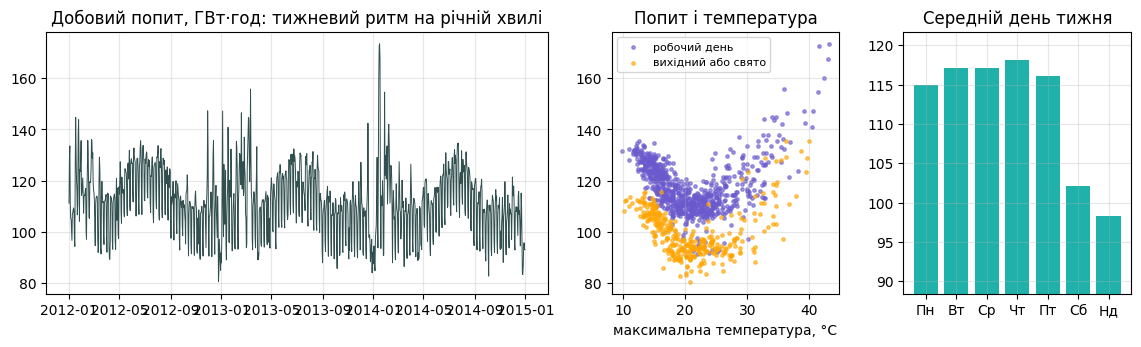

In [3]:
vic = pd.read_csv(f"{BASE}/vic_elec.csv", parse_dates=["ds"])
wide = vic.pivot_table(index="ds", columns="unique_id", values="y")
holiday = vic.query("unique_id == 'Demand'").set_index("ds")["Holiday"].astype(bool)
daily = pd.DataFrame({"demand": wide["Demand"].resample("D").sum() / 2e3,     # half-hourly MW -> GWh per day
                      "temp": wide["Temperature"].resample("D").max(),
                      "holiday": holiday.resample("D").max()})
daily["workday"] = ((daily.index.dayofweek < 5) & ~daily["holiday"]).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), width_ratios=[2.2, 1, 1])
axes[0].plot(daily.index, daily["demand"], color=COLOURS["actual"], linewidth=0.7)
axes[0].set_title("Добовий попит, ГВт·год: тижневий ритм на річній хвилі")
for flag, colour, label in [(1, COLOURS["d"], "робочий день"), (0, COLOURS["c"], "вихідний або свято")]:
    part = daily[daily["workday"] == flag]
    axes[1].scatter(part["temp"], part["demand"], s=6, color=colour, alpha=0.6, label=label)
axes[1].set_title("Попит і температура")
axes[1].set_xlabel("максимальна температура, °C")
axes[1].legend(fontsize=8)
profile = daily.groupby(daily.index.dayofweek)["demand"].mean()
axes[2].bar(["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Нд"], profile, color=COLOURS["b"])
axes[2].set_ylim(profile.min() * 0.9, profile.max() * 1.03)
axes[2].set_title("Середній день тижня")
plt.show()

З графіків видно три речі: **тижневий** сезон (вихідні нижчі), **річний** сезон (зимове опалення, літні
кондиціонери) і **U-подібний** зв'язок із температурою — і холодні, і спекотні дні підвищують попит. ETS і
сезонна ARIMA вміщують лише один сезон; у цьому й проблема кейсу.

In [4]:
y1 = daily["demand"].to_numpy()
temp = daily["temp"].to_numpy()
t1 = np.arange(len(y1))
H1 = 28
origins1 = [len(y1) - H1 * k for k in range(9, 0, -1)]                 # nine four-week windows, April to December 2014
labels1 = [f"{daily.index[e]:%d %b}" for e in origins1]
scale1 = np.mean(np.abs(y1[7:origins1[0]] - y1[:origins1[0] - 7]))    # seasonal naive (week) MAE before the test

X_season = np.column_stack([fourier(t1, 7, 3), fourier(t1, 365.25, 6)])
X_weather = np.column_stack([X_season, temp, temp ** 2, daily["workday"]])


def harmonic(X):
    # Fourier terms for both seasons (plus weather), ARIMA errors without seasonal terms.
    return lambda e: AutoARIMA(season_length=1, d=0, max_p=3, max_q=3).fit(
        y=y1[:e], X=X[:e]).predict(h=H1, X=X[e:e + H1])["mean"]


def prophet1(weather):
    def forecast(e):
        df = pd.DataFrame({"ds": daily.index, "y": y1, "temp": temp, "temp2": temp ** 2,
                           "workday": daily["workday"].to_numpy()})
        m = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
        if weather:
            for column in ("temp", "temp2", "workday"):
                m.add_regressor(column)
        m.fit(df.iloc[:e])
        return m.predict(df.iloc[e:e + H1])["yhat"].to_numpy()
    return forecast


forecasters1 = {
    "seasonal naive (week)": lambda e: np.tile(y1[e - 7:e], 4),
    "ETS (m = 7)": lambda e: AutoETS(season_length=7).fit(y=y1[:e]).predict(h=H1)["mean"],
    "ARIMA (m = 7)": lambda e: AutoARIMA(season_length=7).fit(y=y1[:e]).predict(h=H1)["mean"],
    "MSTL [7, 365]": lambda e: MSTL(season_length=[7, 365]).fit(y=y1[:e]).predict(h=H1)["mean"],
    "harmonic regression": harmonic(X_season),
    "harmonic + weather": harmonic(X_weather),
    "Prophet": prophet1(False),
    "Prophet + weather": prophet1(True),
}

🔮 **Спершу вгадайте.** Вісім прогнозистів, дев'ять чотиритижневих вікон. Хто кращий: ETS лише з тижневим
сезоном чи MSTL з обома? Чи допомагає температура — і наскільки? (Рахується близько двох хвилин.)

In [5]:
scores1, fc1 = backtest(y1, forecasters1, origins1, H1, scale1, labels1)
scores1.loc["harmonic + weather & Prophet + weather"] = np.nan
pair = [np.mean(np.abs(y1[e:e + H1] - (a + b) / 2)) / scale1
        for e, a, b in zip(origins1, fc1["harmonic + weather"], fc1["Prophet + weather"])]
scores1.loc["harmonic + weather & Prophet + weather"] = pair + [np.mean(pair)]
scoreboard(scores1)

,24 Apr,22 May,19 Jun,17 Jul,14 Aug,11 Sep,09 Oct,06 Nov,04 Dec,mean
seasonal naive (week),1.34,0.98,0.56,0.48,1.10,0.56,0.62,0.95,1.25,0.87
ETS (m = 7),0.74,0.80,0.53,0.48,1.03,0.45,0.37,1.01,1.12,0.73
ARIMA (m = 7),0.58,0.61,1.24,0.96,0.57,0.97,0.77,0.52,1.11,0.81
"MSTL [7, 365]",0.78,0.55,0.69,0.56,0.59,0.31,0.45,0.58,0.86,0.60
harmonic regression,0.71,1.05,0.35,0.47,0.35,0.40,0.41,0.52,0.95,0.58
harmonic + weather,0.50,0.73,0.29,0.31,0.20,0.35,0.30,0.33,0.60,0.40
Prophet,0.69,0.60,0.56,0.79,0.38,0.40,0.37,0.55,0.91,0.58
Prophet + weather,0.43,0.30,0.41,0.66,0.27,0.31,0.34,0.39,0.46,0.40
harmonic + weather & Prophet + weather,0.45,0.51,0.30,0.43,0.20,0.33,0.31,0.34,0.51,0.37


**Висновок.**

- **Один сезон програє двом.** ETS і ARIMA з тижневим сезоном мають середній MASE 0,73 і 0,81; MSTL,
  гармонічна регресія і Prophet, які бачать і тиждень, і рік, — 0,58–0,60. Це на чверть менша похибка без
  жодних додаткових даних.
- **Погода — ще третина.** Гармонічна регресія і Prophet з температурою та робочими днями — 0,40 обидва.
  Середнє цих двох — 0,37, найкраще на дошці.
- **ARIMA найнестабільніша**: 0,52–0,61 в одних вікнах і 0,96–1,24 в інших. Середнє ховає цей розкид;
  дивіться на стовпці, а не лише на останній.
- Сезонний наївний тиждень (0,87) програє всім, крім себе самого, — але не набагато: у червні й липні він
  на рівні з ETS.

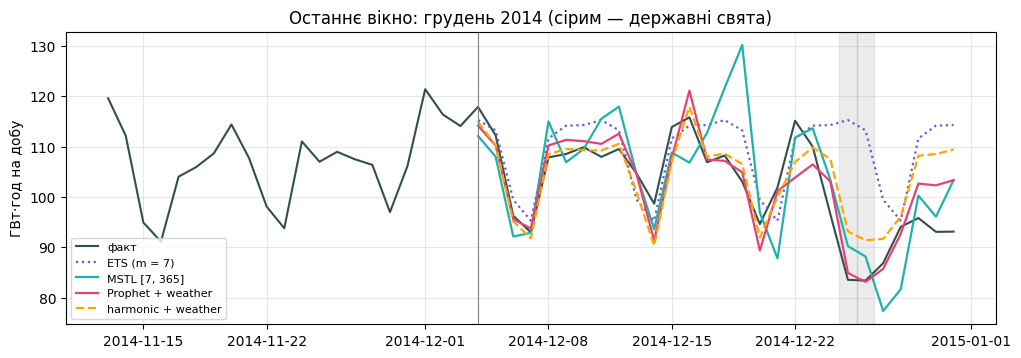

In [6]:
e = origins1[-1]
days = daily.index[e - 21:e + H1]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(days, y1[e - 21:e + H1], color=COLOURS["actual"], linewidth=1.5, label="факт")
for name, colour, line in [("ETS (m = 7)", COLOURS["d"], ":"), ("MSTL [7, 365]", COLOURS["b"], "-"),
                           ("Prophet + weather", COLOURS["a"], "-"), ("harmonic + weather", COLOURS["c"], "--")]:
    ax.plot(daily.index[e:e + H1], fc1[name][-1], line, color=colour, linewidth=1.6, label=name)
for d in daily.index[e:e + H1][daily["holiday"].iloc[e:e + H1].to_numpy()]:
    ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color="grey", alpha=0.15)
ax.axvline(daily.index[e], color="grey", linewidth=0.8)
ax.set_ylabel("ГВт·год на добу")
ax.set_title("Останнє вікно: грудень 2014 (сірим — державні свята)")
ax.legend(loc="lower left", fontsize=8)
plt.show()

**❓ Питання.** Моделі з погодою використовують температуру, яка **справді була**, — це прогноз ex post
(тиждень 7). Яким був би їхній результат у справжньому прогнозі, зробленому 4 грудня, і що варто дати
диспетчерові замість однієї лінії?

### Обговорення і відповіді

**Що змінилося б у справжньому прогнозі?** 4 грудня ніхто не знає температури 20 грудня. Справжня модель
отримала б **прогноз** погоди: на перші кілька днів він точний, далі — дедалі ближчий до кліматичної
норми для цієї дати. Отже, перевага погодних моделей (0,40 проти 0,58) — це **верхня межа**: у перший
тиждень вона майже вся лишається, на третьому-четвертому тижні тане.

А от **робочий день і свята** — відомі наперед. Подивіться на останнє вікно: 25–26 грудня ETS прогнозує
звичайний будній попит (≈ 114 ГВт·год), бо не знає про Різдво; Prophet з ознакою робочого дня опускається
до факту (≈ 84). MSTL теж падає — він пам'ятає минулорічне Різдво через річний сезон, але 27–28 грудня
занижує попит на 10–12 ГВт·год.

**Що дати диспетчерові?** Не одну лінію, а **сценарії**: та сама модель, якій подали прохолодний,
звичайний і спекотний варіанти погоди (як у кейсі зі спекою минулого тижня), плюс календар свят, який
відомий точно.

## 2. 🛒 Walmart, 45 магазинів, тиждень за тижнем

Дані Walmart з тижня 4: тижневі продажі 45 магазинів з лютого 2010 до жовтня 2012 року, з позначкою на
чотирьох святкових тижнях, які позначає сама компанія, — Супербоул, День праці, День подяки, Різдво.
Тижневі дані — саме там, де живе проблема $m = 52{,}18$ з лекції: рік не складається з цілого числа
тижнів.

Спершу сума мережі, потім кожен магазин.

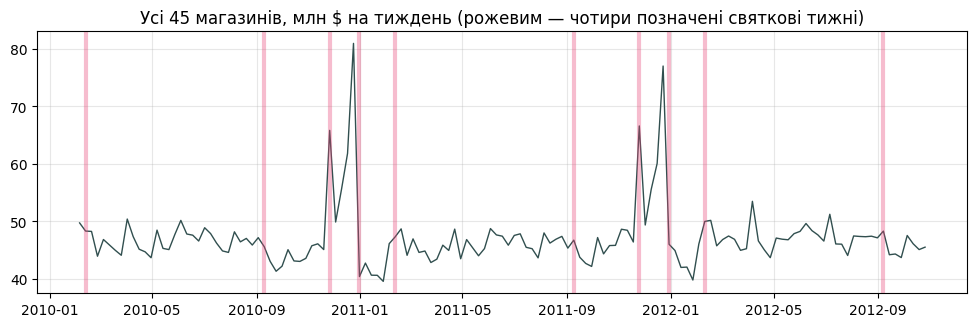

In [7]:
walmart = pd.read_csv(f"{BASE}/walmart.csv", parse_dates=["ds"])
total = walmart.groupby("ds").agg(y=("y", "sum"), holiday=("holiday", "max")).reset_index()
total["y"] /= 1e6                                                       # $ million

fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(total["ds"], total["y"], color=COLOURS["actual"], linewidth=1)
for d in total.loc[total["holiday"] == 1, "ds"]:
    ax.axvline(d, color=COLOURS["a"], alpha=0.35, linewidth=3)
ax.set_title("Усі 45 магазинів, млн $ на тиждень (рожевим — чотири позначені святкові тижні)")
plt.show()

День подяки й Різдво домінують у році; Супербоул і День праці майже не видно. Даних лише **два з половиною
роки**: кожен метод, що оцінює річну форму, бачить її двічі.

Моделі — від знайомих до лекційних:

- **сезонний наївний, $m = 52$** — той самий тиждень минулого року;
- **ETS** і **ARIMA без сезону** — те, що лишається, якщо відмовитися від $m = 52$;
- **MSTL з $m = 52$** — сезон через згладжування;
- **гармонічна регресія**, $K = 10$ пар на справжньому періоді 52,18, з ознакою свят і без неї;
- **Prophet** зі святковими тижнями як holidays.

In [8]:
def weekly_forecasters(y, flag, dates, h):
    t = np.arange(len(y))
    X = fourier(t, 52.18, 10)
    Xh = np.column_stack([X, flag])

    def harmonic(Z):
        return lambda e: AutoARIMA(season_length=1, max_p=3, max_q=3).fit(
            y=y[:e], X=Z[:e]).predict(h=h, X=Z[e:e + h])["mean"]

    def prophet(e):
        holidays = pd.DataFrame({"holiday": "flagged week", "ds": dates[flag == 1]})
        m = Prophet(yearly_seasonality=10, weekly_seasonality=False, daily_seasonality=False,
                    holidays=holidays).fit(pd.DataFrame({"ds": dates[:e], "y": y[:e]}))
        return m.predict(pd.DataFrame({"ds": dates[e:e + h]}))["yhat"].to_numpy()

    return {
        "seasonal naive (m = 52)": lambda e: y[e - 52:e - 52 + h],
        "ETS, no season": lambda e: AutoETS(season_length=1).fit(y=y[:e]).predict(h=h)["mean"],
        "ARIMA, no season": lambda e: AutoARIMA(season_length=1).fit(y=y[:e]).predict(h=h)["mean"],
        "MSTL (m = 52)": lambda e: MSTL(season_length=52).fit(y=y[:e]).predict(h=h)["mean"],
        "harmonic, K = 10": harmonic(X),
        "harmonic + holidays": harmonic(Xh),
        "Prophet + holidays": prophet,
    }


y2 = total["y"].to_numpy()
H2 = 13                                                                 # a quarter ahead
origins2 = [len(y2) - H2 * k for k in (3, 2, 1)]
labels2 = [f"{total['ds'][e]:%d %b %Y}" for e in origins2]
scale2 = np.mean(np.abs(y2[52:origins2[0]] - y2[:origins2[0] - 52]))

🔮 **Спершу вгадайте.** У лекційній тижневій електриці було два роки навчальних даних, і переміг той самий
тиждень минулого року. Чи переможе він і тут?

In [9]:
scores2, fc2 = backtest(y2, weekly_forecasters(y2, total["holiday"].to_numpy(), total["ds"].to_numpy(), H2),
                        origins2, H2, scale2, labels2)
scoreboard(scores2)

,03 Feb 2012,04 May 2012,03 Aug 2012,mean
seasonal naive (m = 52),1.55,1.03,0.68,1.09
"ETS, no season",4.74,2.26,1.31,2.77
"ARIMA, no season",1.58,1.04,1.07,1.23
MSTL (m = 52),1.31,0.80,0.48,0.86
"harmonic, K = 10",1.12,1.43,1.04,1.20
harmonic + holidays,1.13,1.25,1.10,1.16
Prophet + holidays,1.20,0.93,0.67,0.93


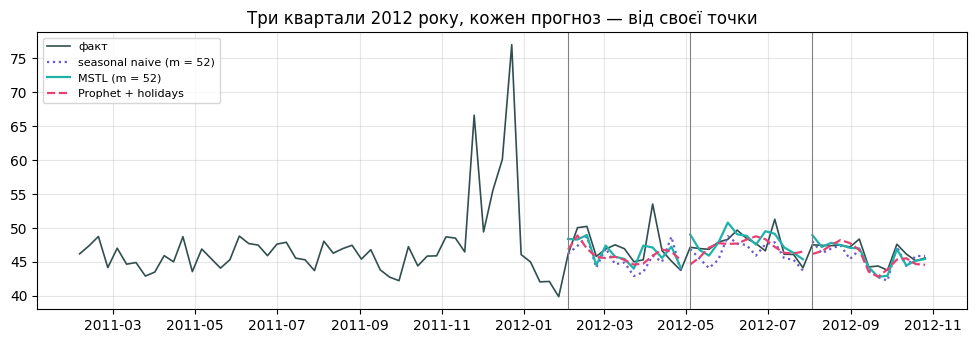

In [10]:
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(total["ds"].iloc[52:], y2[52:], color=COLOURS["actual"], linewidth=1.2, label="факт")
for name, colour, line in [("seasonal naive (m = 52)", COLOURS["d"], ":"), ("MSTL (m = 52)", COLOURS["b"], "-"),
                           ("Prophet + holidays", COLOURS["a"], "--")]:
    for i, e in enumerate(origins2):
        ax.plot(total["ds"].iloc[e:e + H2], fc2[name][i], line, color=colour, linewidth=1.6,
                label=name if i == 0 else None)
for e in origins2:
    ax.axvline(total["ds"].iloc[e], color="grey", linewidth=0.8)
ax.set_title("Три квартали 2012 року, кожен прогноз — від своєї точки")
ax.legend(loc="upper left", fontsize=8)
plt.show()

**Висновок (сума мережі).** Цього разу минулорічний тиждень **не** переміг: MSTL — 0,86, Prophet зі
святами — 0,93, сезонний наївний — 1,09. Моделі без сезону провалюються: ETS — 2,77, ARIMA — 1,23.
Гармонічна регресія з $K = 10$ (1,16–1,20) теж гірша за наївний: десять пар хвиль, оцінених на двох
роках, — забагато.

Лютневе вікно складне для всіх: жоден прогнозист не опустився нижче 1,1.

Один ряд — це одна спроба. Ті самі сім прогнозистів на **кожному магазині** — 45 × 3 вікна. (Близько
чотирьох хвилин: Prophet і регресії перенавчаються по 135 разів.)

In [11]:
rows = {}
for store, g in walmart.groupby("unique_id"):
    y, flag, dates = g["y"].to_numpy() / 1e6, g["holiday"].to_numpy(), g["ds"].to_numpy()
    scale = np.mean(np.abs(y[52:origins2[0]] - y[:origins2[0] - 52]))
    table, fcs = backtest(y, weekly_forecasters(y, flag, dates, H2), origins2, H2, scale)
    combo = [np.mean(np.abs(y[e:e + H2] - (a + b) / 2)) / scale
             for e, a, b in zip(origins2, fcs["MSTL (m = 52)"], fcs["Prophet + holidays"])]
    rows[store] = table["mean"].to_dict() | {"MSTL & Prophet": np.mean(combo)}
stores = pd.DataFrame(rows).T

summary2 = pd.DataFrame({"mean MASE": stores.mean(), "median MASE": stores.median(),
                         "beats last year's week": stores.lt(stores["seasonal naive (m = 52)"], axis=0).mean(),
                         "best of the seven": stores.drop(columns="MSTL & Prophet").idxmin(axis=1)
                         .value_counts().reindex(stores.columns).fillna(0) / len(stores)})
scoreboard(summary2, rules={"mean MASE": "lower", "median MASE": "lower",
                            "beats last year's week": "higher", "best of the seven": "higher"})

,mean MASE,median MASE,beats last year's week,best of the seven
seasonal naive (m = 52),0.99,0.93,0.00,0.07
"ETS, no season",1.56,1.62,0.22,0.02
"ARIMA, no season",1.04,1.04,0.49,0.09
MSTL (m = 52),0.69,0.73,0.91,0.53
"harmonic, K = 10",0.82,0.84,0.64,0.07
harmonic + holidays,0.83,0.83,0.69,0.02
Prophet + holidays,0.80,0.75,0.73,0.20
MSTL & Prophet,0.67,0.68,0.89,0.00


**Висновок (45 магазинів).**

- **MSTL — найкращий із семи на 53% магазинів** і обіграє минулорічний тиждень на 91% з них; середній
  MASE 0,69 проти 0,99 у наївного.
- **Prophet зі святами** — другий (0,80, найкращий на 20% магазинів).
- **Середнє MSTL і Prophet** — 0,67, найнижчий середній MASE на дошці, хоча як окрема модель воно в
  «найкращому з семи» не бере участі.
- **Ознака свят нічого не дає**: гармонічна регресія 0,82 без неї і 0,83 з нею.

Чому не як у лекції, де виграв минулорічний тиждень? Тижневі продажі — це стабільний сезон плюс шум.
Сезонний наївний копіює шум минулого року разом із сезоном; MSTL усереднює форму за двома роками і шум
частково гасить.

**❓ Питання.** Ознака свят майже не змінює ні гармонічну регресію, ні Prophet. Подивіться на дати трьох
тестових кварталів: які з позначених свят у них потрапляють? Чого була б варта ознака з точки початку на
початку листопада?

### Обговорення і відповіді

**Які свята потрапляють у тестові квартали?** Лише два: Супербоул (10 лютого 2012) і День праці
(7 вересня 2012) — ті, яких на графіку майже не видно. День подяки й Різдво — головні піки року — у тест
не потрапили, тож ознака свят і не могла допомогти.

**А з точки початку на початку листопада?** Тоді в горизонт потрапили б обидва великі свята, і саме там
ознака мала б сенс. Але подивіться уважно на графік мережі: рожева лінія різдвяного тижня стоїть **після**
піку. Ознака позначає тиждень, що закінчується 31 грудня, коли продажі вже впали, а пік — тижнем раніше.
Модель зі святами в такому вигляді вивчила б «свято знижує продажі». Перш ніж додавати регресор, перевірте,
**що саме** він позначає.

## 3. 🏨 Поїздки до 76 регіонів Австралії: обрати чи усереднити?

Лекція провела цей експеримент на пулі Track B, якого ви не бачите. Тут він на відкритих даних: квартальна
кількість поїздок із ночівлею до кожного з 76 туристичних регіонів Австралії, 1998–2017, усі мети разом.

Для кожного регіону:

- **обрати** — оцінити ETS, ARIMA і Theta на трьох валідаційних вікнах, лишити найкращу і застосувати її на
  тесті;
- **усереднити** — взяти середнє прогнозів, нічого не обираючи.

Тест — останні два роки (8 кварталів), яких не бачив жоден з підходів.

In [12]:
tourism = pd.read_csv(f"{BASE}/tourism.csv", parse_dates=["ds"])
regions = tourism.groupby(["Region", "ds"], as_index=False)["y"].sum().rename(columns={"Region": "unique_id"})
H3 = 8
test3 = regions.groupby("unique_id").tail(H3)
train3 = regions.drop(test3.index)
names3 = ["ETS", "ARIMA", "Theta"]
sf3 = StatsForecast(models=[AutoETS(season_length=4, alias="ETS"), AutoARIMA(season_length=4, alias="ARIMA"),
                            AutoTheta(season_length=4, alias="Theta"), SeasonalNaive(4, alias="seasonal naive")],
                    freq="QS", n_jobs=-1)
validation = sf3.cross_validation(df=train3, h=H3, n_windows=3, step_size=4)      # three origins, a year apart
tested = sf3.forecast(df=train3, h=H3).merge(test3, on=["unique_id", "ds"])
scale3 = train3.groupby("unique_id")["y"].apply(lambda s: np.mean(np.abs(s.to_numpy()[4:] - s.to_numpy()[:-4])))


def mase_by_series(df, columns):
    return df.groupby("unique_id").apply(
        lambda g: pd.Series({c: np.mean(np.abs(g["y"] - g[c])) for c in columns}), include_groups=False
    ).div(scale3, axis=0)


tested["average of three"] = tested[names3].mean(axis=1)
val3 = mase_by_series(validation, names3)
test_scores3 = mase_by_series(tested, names3 + ["seasonal naive", "average of three"])
picked = val3.idxmin(axis=1)
test_scores3["select on validation"] = [test_scores3.loc[r, picked[r]] for r in test_scores3.index]
test_scores3["oracle: the test winner"] = test_scores3[names3].min(axis=1)
print("вибір обрав:", picked.value_counts().to_dict())

вибір обрав: {'ETS': 30, 'Theta': 25, 'ARIMA': 21}


🔮 **Спершу вгадайте.** Три кандидати: монетка вгадала б переможця тесту в третині випадків. Як часто його
вгадує вибір за трьома валідаційними вікнами?

In [13]:
hit = (picked == test_scores3[names3].idxmin(axis=1)).mean()
print(f"вибір вгадав переможця тесту в {hit:.0%} регіонів (монетка: 33%)")
summary3 = pd.DataFrame({"mean MASE": test_scores3.mean(), "median MASE": test_scores3.median(),
                         "worst region": test_scores3.max(),
                         "beats seasonal naive": test_scores3.lt(test_scores3["seasonal naive"], axis=0).mean()})
scoreboard(summary3, rules={"mean MASE": "lower", "median MASE": "lower", "worst region": "lower",
                            "beats seasonal naive": "higher"})

вибір вгадав переможця тесту в 36% регіонів (монетка: 33%)


,mean MASE,median MASE,worst region,beats seasonal naive
ETS,1.11,1.15,2.01,0.54
ARIMA,1.23,1.21,2.52,0.43
Theta,1.06,1.06,1.96,0.66
seasonal naive,1.18,1.17,1.98,0.00
average of three,1.10,1.09,2.08,0.59
select on validation,1.13,1.14,2.11,0.53
oracle: the test winner,1.00,0.93,1.96,0.70


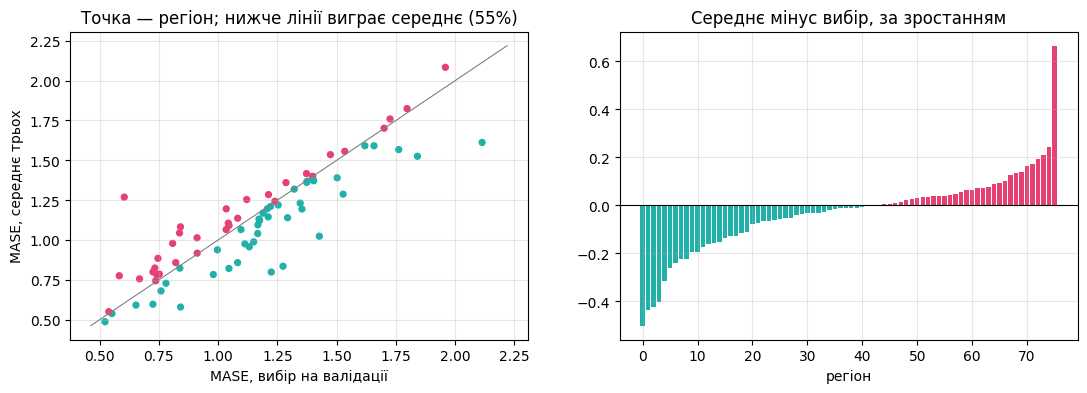

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
a, b = test_scores3["select on validation"], test_scores3["average of three"]
axes[0].scatter(a, b, s=18, color=np.where(b < a, COLOURS["b"], COLOURS["a"]))
lim = [min(a.min(), b.min()) * 0.95, max(a.max(), b.max()) * 1.05]
axes[0].plot(lim, lim, color="grey", linewidth=0.8)
axes[0].set_xlabel("MASE, вибір на валідації")
axes[0].set_ylabel("MASE, середнє трьох")
axes[0].set_title(f"Точка — регіон; нижче лінії виграє середнє ({(b < a).mean():.0%})")
gap = (b - a).sort_values()
axes[1].bar(range(len(gap)), gap, color=np.where(gap < 0, COLOURS["b"], COLOURS["a"]))
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Середнє мінус вибір, за зростанням")
axes[1].set_xlabel("регіон")
plt.show()

**Висновок.**

- **Вибір вгадав переможця тесту лише в 36% регіонів** — майже як монетка (33%).
- **Середнє трьох** (1,10) краще за вибір (1,13) за середнім і медіаною і обігрує сезонний наївний на 59%
  регіонів проти 53% у вибору. На точковій діаграмі середнє краще в 55% регіонів.
- **Найкраща окрема модель тут — Theta** (1,06). Якби ви знали це наперед, обрали б її; на валідації вона
  виграла лише в 25 регіонах із 76.
- Усі MASE близькі до 1: останні два роки виявилися складнішими за історію для всіх моделей, і це
  нагадування, що тест — не повторення валідації.

**❓ Питання.** Рядок «оракул» — найкраще, що можна було б зробити, якби ви завжди знали переможця. Яку
частину розриву між «обрати» і оракулом закриває середнє? Чому вибір на трьох вікнах ледве кращий за
монетку — або гірший?

### Обговорення і відповіді

**Яку частину розриву закриває середнє?** Від вибору (1,13) до оракула (1,00) — 0,13. Середнє (1,10)
закриває ≈ 0,03, тобто **близько чверті** — нічого не обираючи і нічим не ризикуючи.

**Чому вибір майже як монетка?** Три моделі близькі одна до одної, а три валідаційні вікна по 8 кварталів
— мало, щоб розрізнити різницю в кілька сотих MASE. Ранг на валідації здебільшого відображає, яке вікно
випало, а не яка модель краща. Тест — ще одне вікно, з іншими сюрпризами. Середнє ж не залежить від того,
хто виграв минулого разу: воно лише гасить частину похибок кожної моделі.

## 4. 🍽️ Австралійці їдять поза домом: рецепт Lab 8 від початку до кінця

Місячний оборот кафе, ресторанів і закладів їжі на винос Австралії, усі штати разом, 1982–2018. Саме
національна сума, а не штат: жоден ряд Track B не є національною сумою.

Сьогоднішня Lab 8 крок за кроком:

1. **логарифм**, бо розмах сезону росте з рівнем;
2. **валідація** — ETS, ARIMA і MSTL на шести ковзних 12-місячних вікнах перед тестом;
3. **комбінація** — просте середнє трьох;
4. **інтервал** — три рецепти, оцінені покриттям і показником Вінклера;
5. **прогноз** — перенавчити на всьому і здати.

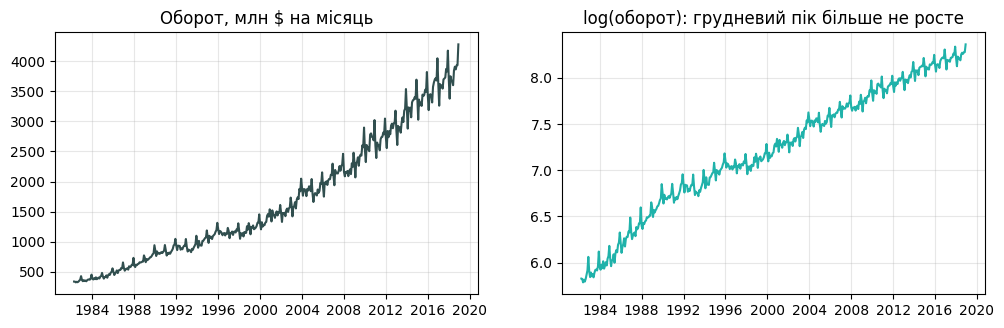

In [15]:
retail = pd.read_csv(f"{BASE}/aus_retail.csv", parse_dates=["Month"])
national = (retail.groupby(["Industry", "Month"], as_index=False)["Turnover"].sum()
            .rename(columns={"Industry": "unique_id", "Month": "ds", "Turnover": "y"}))
cafes = national.query("unique_id == 'Cafes, restaurants and takeaway food services'").reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].plot(cafes["ds"], cafes["y"], color=COLOURS["actual"])
axes[0].set_title("Оборот, млн $ на місяць")
axes[1].plot(cafes["ds"], np.log(cafes["y"]), color=COLOURS["b"])
axes[1].set_title("log(оборот): грудневий пік більше не росте")
plt.show()

In [16]:
H4, WINDOWS = 12, 6
MEMBERS = ["ETS", "ARIMA", "MSTL"]


def members():
    return [AutoETS(season_length=12, alias="ETS"), AutoARIMA(season_length=12, alias="ARIMA"),
            MSTL(season_length=12, alias="MSTL")]


logged = cafes.assign(y=np.log(cafes["y"]))
train4, test4 = logged.iloc[:-H4], cafes.iloc[-H4:]
sf4 = StatsForecast(models=members(), freq="MS")
cv4 = sf4.cross_validation(df=train4, h=H4, n_windows=WINDOWS, step_size=H4)
cv4["combination"] = cv4[MEMBERS].mean(axis=1)
past4 = cafes["y"].iloc[:-H4].to_numpy()
scale4 = np.mean(np.abs(past4[12:] - past4[:-12]))                     # seasonal naive MAE, $ million
val4 = cv4.groupby("cutoff").apply(
    lambda g: pd.Series({c: np.mean(np.abs(np.exp(g["y"]) - np.exp(g[c]))) / scale4 for c in MEMBERS + ["combination"]}),
    include_groups=False).T
val4.columns = [f"from {c:%b %Y}" for c in val4.columns]
val4["mean"] = val4.mean(axis=1)

🔮 **Спершу вгадайте.** Шість валідаційних вікон. Чи виграє один учасник усі шість? Де опиниться комбінація?

In [17]:
scoreboard(val4)

,from Dec 2011,from Dec 2012,from Dec 2013,from Dec 2014,from Dec 2015,from Dec 2016,mean
ETS,0.39,0.64,0.38,0.60,1.13,0.69,0.64
ARIMA,0.65,0.46,0.37,0.41,0.37,0.61,0.48
MSTL,0.43,0.42,0.38,0.69,0.42,0.91,0.54
combination,0.46,0.50,0.37,0.56,0.49,0.73,0.52


**Висновок.**

- **Жоден учасник не виграє всі шість вікон.** ETS найкращий з грудня 2011, MSTL — з грудня 2012, ARIMA — у
  2014–2016 роках. У 2015 році ETS раптом найгірший (1,13), у 2016 — MSTL (0,91).
- **Комбінація жодного разу не найгірша** і за середнім друга (0,52) після ARIMA (0,48).
- Вибір на валідації взяв би **ARIMA**. Подивимося, чи це було правильно.

Тепер тестовий рік — 2018, не торканий. Учасників перенавчаємо на всьому, що було до нього. Вибір бере
учасника з найкращим середнім на валідації; комбінація нічого не обирає.

Три інтервали для комбінації:

- **власний** 80% інтервал кожного учасника — для порівняння;
- **усереднені межі** — середнє нижніх і верхніх меж учасників;
- **conformal** — похибки комбінації на шести валідаційних вікнах, **окремо для кожного кроку горизонту**
  (6 похибок для $h = 1$, 6 для $h = 2$, …), і їхні 10% та 90% квантилі, додані до нового прогнозу.
  Conformal-інтервал у лекції брав одне вікно і провалився; цей бере шість.

In [18]:
fc4 = sf4.forecast(df=train4, h=H4, level=[80])
fc4["combination"] = fc4[MEMBERS].mean(axis=1)
actual4 = test4["y"].to_numpy()
best_member = val4.loc[MEMBERS, "mean"].idxmin()

points = {m: np.exp(fc4[m].to_numpy()) for m in MEMBERS}
points["combination"] = np.exp(fc4["combination"].to_numpy())
points[f"select on validation ({best_member})"] = points[best_member]
point_scores = pd.Series({k: np.mean(np.abs(actual4 - v)) / scale4 for k, v in points.items()}, name="test MASE")

cv4["step"] = cv4.groupby("cutoff").cumcount()                         # 0 .. 11: the horizon step
errors = (cv4["y"] - cv4["combination"]).groupby(cv4["step"])          # log errors, six per step
q_lo, q_hi = errors.quantile(0.10).to_numpy(), errors.quantile(0.90).to_numpy()

intervals = {f"{m}'s own": (np.exp(fc4[f"{m}-lo-80"]), np.exp(fc4[f"{m}-hi-80"])) for m in MEMBERS}
intervals["averaged bounds"] = (np.exp(fc4[[f"{m}-lo-80" for m in MEMBERS]].mean(axis=1)),
                                np.exp(fc4[[f"{m}-hi-80" for m in MEMBERS]].mean(axis=1)))
intervals["conformal, six windows"] = (np.exp(fc4["combination"] + q_lo), np.exp(fc4["combination"] + q_hi))
interval_scores = pd.DataFrame({k: {"coverage": coverage(actual4, np.asarray(lo), np.asarray(hi)),
                                    "Winkler": winkler(actual4, np.asarray(lo), np.asarray(hi)),
                                    "mean width": float(np.mean(np.asarray(hi) - np.asarray(lo)))}
                                for k, (lo, hi) in intervals.items()}).T

🔮 **Спершу вгадайте.** Чи обрав вибір правильного учасника для 2018 року? Який інтервал найближчий до 80%
покриття — і чи найвужчий найкращий за Вінклером?

In [19]:
display(scoreboard(point_scores))
scoreboard(interval_scores, rules={"coverage": 0.8, "Winkler": "lower", "mean width": "lower"})

,test MASE
ETS,0.49
ARIMA,0.61
MSTL,1.03
combination,0.41
select on validation (ARIMA),0.61


,coverage,Winkler,mean width
ETS's own,1.00,412.59,412.59
ARIMA's own,1.00,445.59,445.59
MSTL's own,1.00,366.10,366.10
averaged bounds,1.00,408.29,408.29
"conformal, six windows",0.75,192.57,155.28


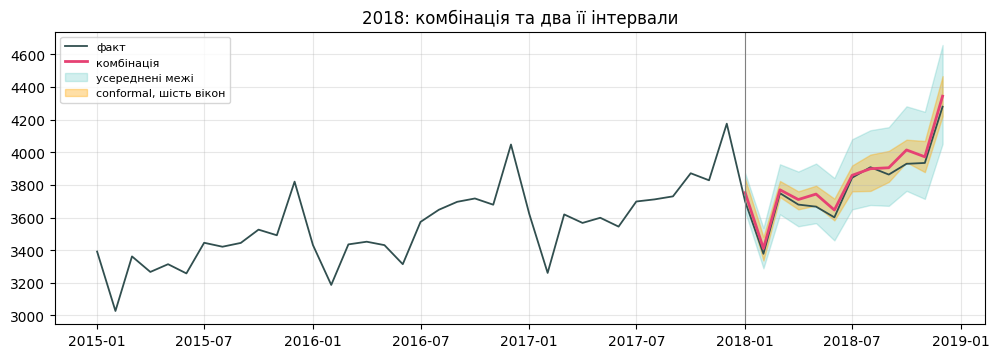

In [20]:
months = test4["ds"]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(cafes["ds"].iloc[-48:], cafes["y"].iloc[-48:], color=COLOURS["actual"], linewidth=1.3, label="факт")
ax.plot(months, points["combination"], color=COLOURS["a"], linewidth=2, label="комбінація")
lo, hi = intervals["averaged bounds"]
ax.fill_between(months, lo, hi, color=COLOURS["b"], alpha=0.2, label="усереднені межі")
lo, hi = intervals["conformal, six windows"]
ax.fill_between(months, lo, hi, color=COLOURS["c"], alpha=0.35, label="conformal, шість вікон")
ax.axvline(months.iloc[0], color="grey", linewidth=0.8)
ax.set_title("2018: комбінація та два її інтервали")
ax.legend(loc="upper left", fontsize=8)
plt.show()

**Висновок.**

- **Вибір помилився.** На 2018 році ARIMA — 0,61, а ETS — 0,49. **Комбінація — 0,41**, найкраща з усіх, хоча
  на валідації не перемогла жодного разу.
- MSTL на тесті слабкий (1,03), і все одно комбінація з ним краща за будь-якого учасника окремо.
- **Інтервали учасників і усереднені межі покривають 12 місяців із 12** — вони заширокі (≈ 410 млн $
  завширшки). Conformal із шести вікон утричі вужчий (≈ 155 млн $), покриває 9 з 12 (75% при цілі 80%) і має
  вдвічі кращий показник Вінклера (193 проти 408).

### Чи досить одного ряду? Рецепт як функція, на всіх 20 галузях

Один ряд — одна історія. Ті самі п'ять кроків, зібрані у функцію, на кожній національній галузі роздрібу —
і ця функція і є вашою Lab 8. (Близько двох хвилин.)

In [21]:
def lab8_recipe(df, h=12, windows=6):
    # Steps 1-4 for every series in df (columns unique_id, ds, y > 0); returns one row per series.
    logged = df.assign(y=np.log(df["y"]))
    test = df.groupby("unique_id").tail(h)
    train = logged.drop(test.index)
    sf = StatsForecast(models=members(), freq="MS", n_jobs=-1)
    cv = sf.cross_validation(df=train, h=h, n_windows=windows, step_size=h)
    cv["combination"] = cv[MEMBERS].mean(axis=1)
    cv["step"] = cv.groupby(["unique_id", "cutoff"]).cumcount()
    fc = sf.forecast(df=train, h=h, level=[80]).merge(test, on=["unique_id", "ds"])
    fc["combination"] = fc[MEMBERS].mean(axis=1)
    fc["step"] = fc.groupby("unique_id").cumcount()
    rows = {}
    for uid, g in fc.groupby("unique_id"):
        past = df.loc[df["unique_id"] == uid, "y"].to_numpy()[:-h]
        scale = np.mean(np.abs(past[12:] - past[:-12]))
        v = cv[cv["unique_id"] == uid]
        val = {m: np.mean(np.abs(np.exp(v["y"]) - np.exp(v[m]))) for m in MEMBERS}
        pick = min(val, key=val.get)
        err = (v["y"] - v["combination"]).groupby(v["step"])
        lo = np.exp(g["combination"].to_numpy() + err.quantile(0.10).to_numpy())
        hi = np.exp(g["combination"].to_numpy() + err.quantile(0.90).to_numpy())
        alo = np.exp(g[[f"{m}-lo-80" for m in MEMBERS]].mean(axis=1).to_numpy())
        ahi = np.exp(g[[f"{m}-hi-80" for m in MEMBERS]].mean(axis=1).to_numpy())
        y, mase = g["y"].to_numpy(), lambda f: np.mean(np.abs(g["y"] - np.exp(f))) / scale
        rows[uid] = {**{m: mase(g[m]) for m in MEMBERS}, "combination": mase(g["combination"]),
                     "select on validation": mase(g[pick]), "picked": pick,
                     "coverage, averaged": coverage(y, alo, ahi), "coverage, conformal": coverage(y, lo, hi),
                     "Winkler, averaged": winkler(y, alo, ahi) / scale, "Winkler, conformal": winkler(y, lo, hi) / scale}
    return pd.DataFrame(rows).T


industries = lab8_recipe(national)
numeric = industries.drop(columns="picked").astype(float)
summary4 = pd.DataFrame({"mean": numeric.mean(), "median": numeric.median()})
print("комбінація краща за вибір на", f"{(numeric['combination'] < numeric['select on validation']).mean():.0%}",
      "галузей; вибір обрав:", industries["picked"].value_counts().to_dict())
scoreboard(summary4.T, rules={"ETS": "lower", "ARIMA": "lower", "MSTL": "lower", "combination": "lower",
                              "select on validation": "lower", "coverage, averaged": 0.8,
                              "coverage, conformal": 0.8, "Winkler, averaged": "lower",
                              "Winkler, conformal": "lower"})

комбінація краща за вибір на 50% галузей; вибір обрав: {'ARIMA': 8, 'ETS': 7, 'MSTL': 5}


,ETS,ARIMA,MSTL,combination,select on validation,"coverage, averaged","coverage, conformal","Winkler, averaged","Winkler, conformal"
mean,0.65,0.65,0.80,0.66,0.66,0.97,0.79,3.83,2.84
median,0.65,0.60,0.75,0.66,0.65,1.00,0.83,3.86,2.79


**Висновок (20 галузей).**

- **Комбінація і вибір у середньому рівні** (0,66 і 0,66), комбінація краща в 10 галузях із 20. Вибір не
  дає переваги — але й рішення, яке ухвалює вибір, нічого не коштує комбінації.
- **MSTL — найслабший учасник** на місячних даних (0,80): з одним сезоном він лише STL плюс ETS для рівня.
- **Усереднені межі покривають 97% місяців** — інтервал, якому не можна вірити, бо він ніколи не помиляється.
  **Conformal із шести вікон — 79%**, майже точно 80%, і кращий показник Вінклера (2,84 проти 3,83, у
  одиницях MASE).
- Кейс з кафе — один із найвдаліших для комбінації; на типовому ряді вона не краща за вибір, а такий самий.
  Аргумент на її користь — не точність у середньому, а відсутність ризику помилитися з вибором.

**❓ Питання.** Ряд вашої Lab 8 — один із цих рядків. Які з сьогоднішніх рішень ви ухвалили б ще до того,
як побачили свою валідаційну таблицю, — логарифм чи ні, які учасники, комбінувати чи обирати, який
інтервал, — а які має вирішити таблиця?

### Обговорення і відповіді

**До таблиці** — те, що не залежить від одного вікна:

- **логарифм** — за графіком: чи росте розмах сезону з рівнем;
- **учасники** — ETS, ARIMA, MSTL, обрані заздалегідь, а не за результатом;
- **комбінувати**, а не обирати — кейси 3 і 4 показують, що вибір ледве кращий за монетку;
- **conformal-інтервал з усіх валідаційних вікон**, окремо для кожного кроку горизонту.

**Таблиця вирішує** лише те, що вона справді може показати: чи комбінація обігрує сезонний наївний на
валідації, чи немає учасника, зламаного в **кожному** вікні (тоді його прибирають — за правилом,
сформульованим до того, як ви побачили таблицю), і наскільки відкалібрований інтервал на валідації.
Якщо після таблиці ви змінюєте рецепт — скажіть про це у звіті і поясніть чому.

## Що з цього взяти на сьогоднішню лабораторну

| Кейс | Що порівнювали | Що вирішило |
|---|---|---|
| ⚡ Електрика | один сезон проти двох, з погодою і без | два сезони кращі за один; погода краща за обидва — ex post |
| 🛒 Walmart | минулорічний тиждень проти MSTL, гармонік, Prophet | при 2,5 роках — MSTL, а не минулорічний тиждень, на більшості магазинів |
| 🏨 Туризм | вибір на валідації проти середнього | вибір близький до монетки; середнє нічого не коштує |
| 🍽️ Їжа поза домом | три учасники, три інтервали | conformal із шести вікон — відкалібрований |

**Lab 8** — це кейс 4 на вашому власному ряді Track B: логарифм, якщо розмах росте; ETS + ARIMA + MSTL з
валідацією на ковзних вікнах; комбінація як прогноз; conformal-інтервал із валідаційних похибок — оцінений,
пояснений, зданий.